In [125]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.segmentation import clear_border

In [126]:
def processar_chave(caminho):
    imagem = cv2.imread(caminho)

    if imagem is None:
        raise FileNotFoundError(caminho)

    gray = cv2.cvtColor(
        imagem,
        cv2.COLOR_BGR2GRAY
    )

    blur = cv2.GaussianBlur(gray, (5, 5), 0)

    _, binary = cv2.threshold(
        blur,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    binary_inverted = cv2.bitwise_not(binary)

    kernel = np.ones((11, 11), np.uint8)

    closed = cv2.morphologyEx(
        binary_inverted,
        cv2.MORPH_CLOSE,
        kernel
    )

    opened = cv2.morphologyEx(
        closed,
        cv2.MORPH_OPEN,
        kernel
    )

    kernel2 = np.ones((15, 15), np.uint8)
    
    cleaned = cv2.morphologyEx(
        opened,
        cv2.MORPH_CLOSE,
        kernel2
    )

    clear_b = clear_border(cleaned)

    contours, _ = cv2.findContours(
        clear_b,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_NONE
    )

    if not contours:
        raise ValueError("Nenhum contorno encontrado")

    contorno = max(contours, key=cv2.contourArea)

    mascara = np.zeros_like(cleaned)

    cv2.drawContours(
        mascara,
        [contorno],
        -1,
        255,
        cv2.FILLED
    )

    return imagem, mascara, contorno

In [127]:
imagem_a, mascara_a, contorno_a = processar_chave(
    "../imagens/PD 442.jpeg"
)

In [128]:
imagem_b, mascara_b, contorno_b = processar_chave(
    "../imagens/Stam 1500.jpeg"
)

In [129]:

def rotacionar_chave(mascara):
    pontos = cv2.findNonZero(mascara)

    if pontos is None:
        raise ValueError("Máscara vazia")

    pontos = pontos.reshape(-1, 2).astype(np.float32)

    media, autovetores = cv2.PCACompute(
        pontos,
        mean=None
    )

    centro = tuple(media[0].astype(float))
    vetor_principal = autovetores[0]

    angulo = np.degrees(
        np.arctan2(
            vetor_principal[1],
            vetor_principal[0]
        )
    )

    rotation_angle = ((angulo + 90) % 180) - 90

    matriz = cv2.getRotationMatrix2D(
        centro,
        float(rotation_angle),
        1.0
    )

    h, w = mascara.shape

    cos = abs(matriz[0, 0])
    sin = abs(matriz[0, 1])

    novo_w = int(np.ceil(h * sin + w * cos))
    novo_h = int(np.ceil(h * cos + w * sin))

    matriz[0, 2] += novo_w / 2 - centro[0]
    matriz[1, 2] += novo_h / 2 - centro[1]

    rotacionada = cv2.warpAffine(
        mascara,
        matriz,
        (novo_w, novo_h),
        flags=cv2.INTER_NEAREST,
        borderValue=0
    )

    return rotacionada, rotation_angle


Rotação A: -87.91°
Rotação B: -89.97°


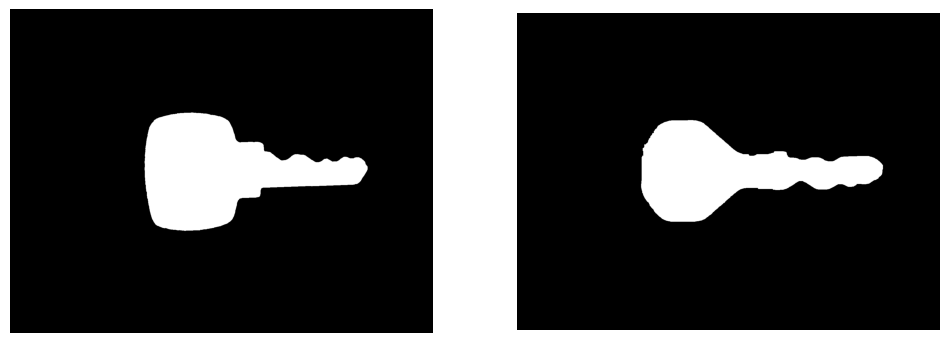

In [130]:
rot_a, angulo_a = rotacionar_chave(mascara_a)
rot_b, angulo_b = rotacionar_chave(mascara_b)

print(f"Rotação A: {angulo_a:.2f}°")
print(f"Rotação B: {angulo_b:.2f}°")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(rot_a, cmap="gray")
axes[1].imshow(rot_b, cmap="gray")

for ax in axes:
    ax.axis("off")

plt.show()

In [131]:
def normalizar_posicao(mascara, tamanho=(500, 200)):
    pontos = cv2.findNonZero(mascara)

    if pontos is None:
        raise ValueError("Máscara vazia")

    x, y, w, h = cv2.boundingRect(pontos)

    recorte = mascara[y:y+h, x:x+w]

    largura_alvo, altura_alvo = tamanho

    escala = min(
        largura_alvo / w,
        altura_alvo / h
    )

    nova_largura = max(1, round(w * escala))
    nova_altura = max(1, round(h * escala))

    redimensionada = cv2.resize(
        recorte,
        (nova_largura, nova_altura),
        interpolation=cv2.INTER_NEAREST
    )

    resultado = np.zeros(
        (altura_alvo, largura_alvo),
        dtype=np.uint8
    )

    inicio_x = (largura_alvo - nova_largura) // 2
    inicio_y = (altura_alvo - nova_altura) // 2

    resultado[
        inicio_y:inicio_y + nova_altura,
        inicio_x:inicio_x + nova_largura
    ] = redimensionada

    return resultado

In [132]:
normal_a = normalizar_posicao(rot_a)
normal_b = normalizar_posicao(rot_b)

In [133]:
def calcular_iou(mascara_a, mascara_b):
    a = mascara_a > 0
    b = mascara_b > 0

    intersecao = np.logical_and(a, b)
    uniao = np.logical_or(a, b)

    total_intersecao = np.sum(intersecao)
    total_uniao = np.sum(uniao)

    if total_uniao == 0:
        raise ValueError("As máscaras estão vazias")

    return total_intersecao / total_uniao


iou = calcular_iou(normal_a, normal_b)

print(f"IoU: {iou:.4f}")
print(f"Sobreposição: {iou * 100:.2f}%")


IoU: 0.6286
Sobreposição: 62.86%


In [134]:
from scipy.spatial.distance import directed_hausdorff

def calcular_hausdorff(mascara_a, mascara_b):
    contornos_a, _ = cv2.findContours(
        mascara_a,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_NONE
    )

    contornos_b, _ = cv2.findContours(
        mascara_b,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_NONE
    )

    if not contornos_a or not contornos_b:
        raise ValueError("Contorno não encontrado")

    contorno_a = max(contornos_a, key=cv2.contourArea)
    contorno_b = max(contornos_b, key=cv2.contourArea)

    pontos_a = contorno_a.reshape(-1, 2)
    pontos_b = contorno_b.reshape(-1, 2)

    distancia_ab = directed_hausdorff(
        pontos_a,
        pontos_b
    )[0]

    distancia_ba = directed_hausdorff(
        pontos_b,
        pontos_a
    )[0]

    return max(distancia_ab, distancia_ba)


hausdorff = calcular_hausdorff(normal_a, normal_b)

print(f"Distância de Hausdorff: {hausdorff:.2f} pixels")


Distância de Hausdorff: 51.97 pixels


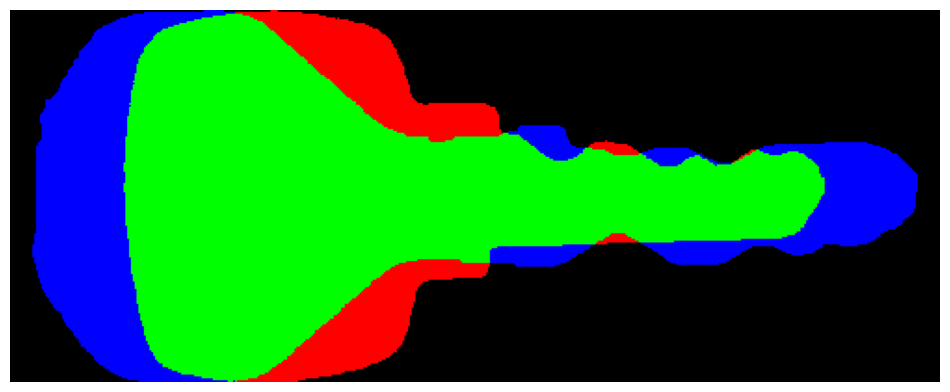

In [135]:
def visualizar_diferencas(mascara_a, mascara_b):
    a = mascara_a > 0
    b = mascara_b > 0

    comum = np.logical_and(a, b)

    somente_a = np.logical_and(
        a,
        np.logical_not(b)
    )

    somente_b = np.logical_and(
        b,
        np.logical_not(a)
    )

    resultado = np.zeros(
        (mascara_a.shape[0], mascara_a.shape[1], 3),
        dtype=np.uint8
    )

    # Cores RGB
    resultado[comum] = [0, 255, 0]
    resultado[somente_a] = [255, 0, 0]
    resultado[somente_b] = [0, 0, 255]

    return resultado


comparacao = visualizar_diferencas(normal_a, normal_b)

plt.figure(figsize=(12, 5))
plt.imshow(comparacao)
plt.axis("off")
plt.show()


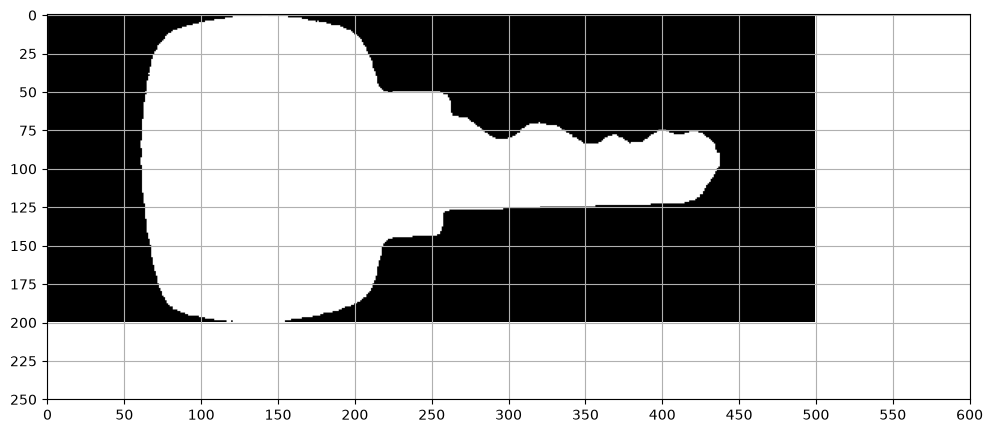

In [136]:
plt.figure(figsize=(12, 5))
plt.imshow(normal_a, cmap="gray")
plt.xticks(np.arange(0, 601, 50))
plt.yticks(np.arange(0, 251, 25))
plt.grid()
plt.show()

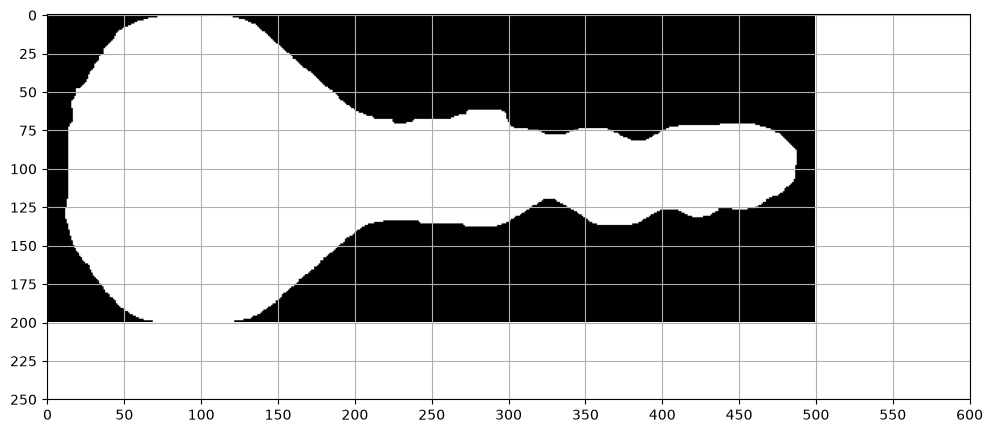

In [137]:
plt.figure(figsize=(12, 5))
plt.imshow(normal_b, cmap="gray")
plt.xticks(np.arange(0, 601, 50))
plt.yticks(np.arange(0, 251, 25))
plt.grid()
plt.show()

In [143]:
x1, y1 = 250, 50
x2, y2 = 500, 150

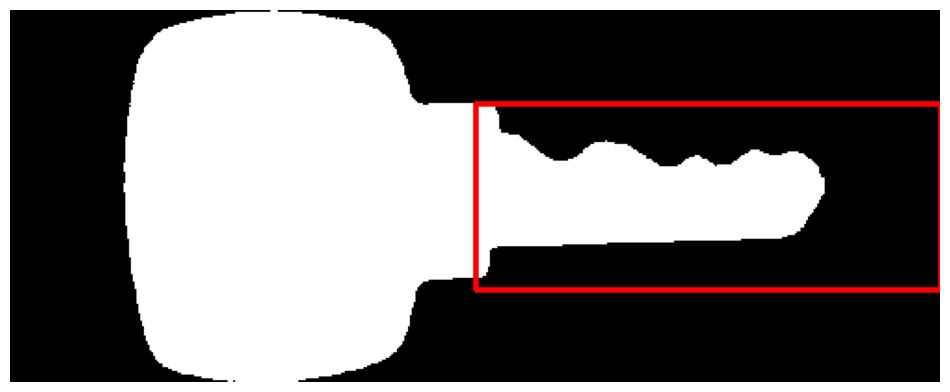

In [144]:
visualizacao = cv2.cvtColor(
    normal_a,
    cv2.COLOR_GRAY2RGB
)

cv2.rectangle(
    visualizacao,
    (x1, y1),
    (x2, y2),
    (255, 0, 0),
    2
)

plt.figure(figsize=(12, 5))
plt.imshow(visualizacao)
plt.axis("off")
plt.show()

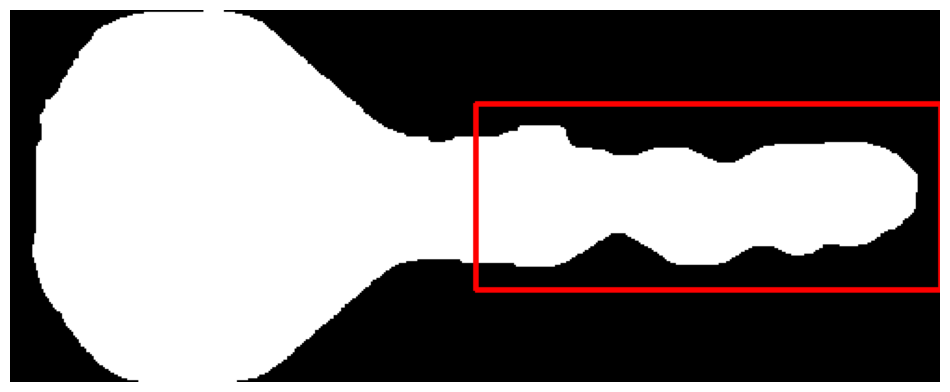

In [145]:
visualizacao = cv2.cvtColor(
    normal_b,
    cv2.COLOR_GRAY2RGB
)

cv2.rectangle(
    visualizacao,
    (x1, y1),
    (x2, y2),
    (255, 0, 0),
    2
)

plt.figure(figsize=(12, 5))
plt.imshow(visualizacao)
plt.axis("off")
plt.show()

In [146]:
roi_a = normal_a[y1:y2, x1:x2]
roi_b = normal_b[y1:y2, x1:x2]

iou_dentes = calcular_iou(roi_a, roi_b)

print(f"IoU global: {iou:.4f}")
print(f"IoU dos dentes: {iou_dentes:.4f}")

IoU global: 0.6286
IoU dos dentes: 0.6259


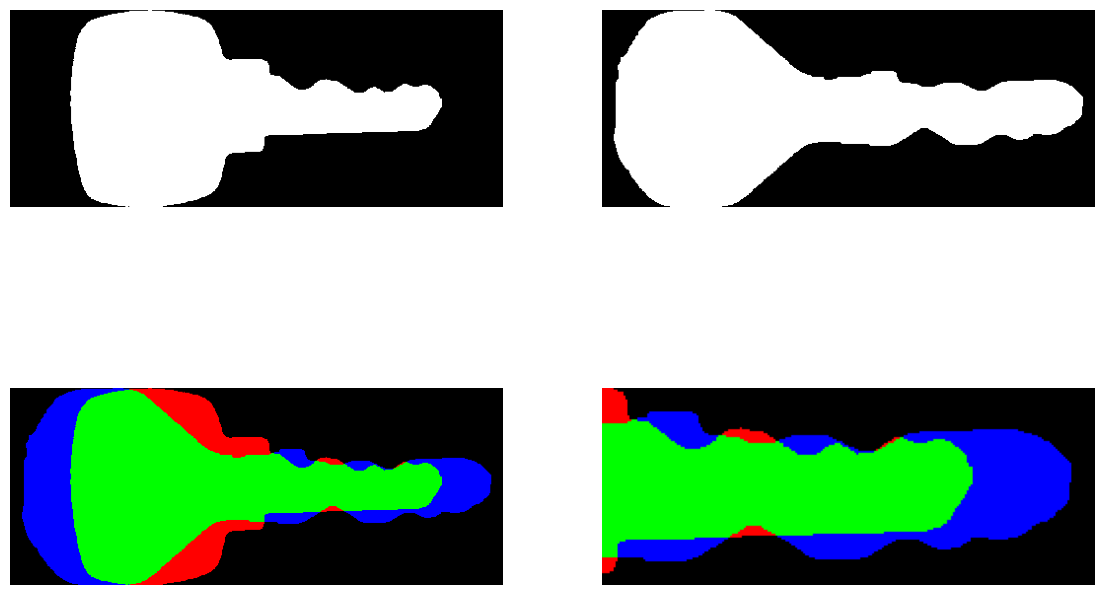

In [147]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].imshow(normal_a, cmap="gray")
axes[0, 1].imshow(normal_b, cmap="gray")

axes[1, 0].imshow(comparacao)

comparacao_dentes = visualizar_diferencas(
    roi_a,
    roi_b
)

axes[1, 1].imshow(comparacao_dentes)

for ax in axes.flat:
    ax.axis("off")

plt.show()
